# Netflix Genre Classification

Predicting a Netflix title's primary genre from its title and description with a bag-of-words Multinomial Naive Bayes model.

Course project for MIS 515 (Programming Data-Driven Applications), San Diego State University, Fall 2025. Dataset: [Netflix Movies and TV Shows](https://www.kaggle.com/datasets/shivamb/netflix-shows) on Kaggle.

## 1. Load the data

In [1]:
# MIS 515 - Project 2
# Netflix Genre Classification - Group 16 (Long Nguyen and Yarely Virgen)

import pandas as pd
from pathlib import Path

# Use a local copy if there is one (data/netflix_titles.csv), otherwise download it from Kaggle
local_csv = Path("data/netflix_titles.csv")
if local_csv.exists():
    df = pd.read_csv(local_csv)
else:
    import kagglehub
    path = kagglehub.dataset_download("shivamb/netflix-shows")
    df = pd.read_csv(f"{path}/netflix_titles.csv")

print("Rows:", len(df))
df.head()

Rows: 8807


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:

# For this project we are using sklearn as the main machine learning model developing

import pandas as pd                    # This is for the tables
import matplotlib.pyplot as plt        # making some visualizations just like our previous project (feel free to change the appearances of the charts)
from sklearn.model_selection import train_test_split          # I added this to split the csv file we will use for the project into 2 parts, the first part I will use for training the model and the second part I will use for testing it)
from sklearn.feature_extraction.text import CountVectorizer   # This turns texts from title descriptions into numbers that make it possible to train the model through "tokens" (this is similar to training AI models, of course very dumbed down)
from sklearn.naive_bayes import MultinomialNB                 # This is the actual classification part, which is the model itself which uses probabilities to classify genres
from sklearn.metrics import accuracy_score, classification_report  # I added this to make sure we get a report on how the model did after testing

# make sure plots show up inside the notebook
%matplotlib inline


## 2. Clean the data

In [3]:
# Cleaning data #

# Drop show id column
df = df.drop(columns=['show_id'])

# Drop rows with missing description or listed_in
df = df.dropna(subset=['description', 'listed_in'])

# Remove unnecessary whitespace
df['title'] = df['title'].str.strip()

# Drop exact duplicate rows (same title + description)
df = df.drop_duplicates(subset=['title', 'description'])

# Cleaner text columns, make everything lowercase so model doesn't take 2 tokens for the same word
def good_text(text):
  text = str(text).lower()
  text = text.strip()
  return text

df['title'] = df['title'].apply(good_text)
df['description'] = df['description'].apply(good_text)
df['listed_in'] = df['listed_in'].apply(good_text)

# There should only be two types: Movie or Tv show
type_allowed = ['Movie', 'TV Show']
for film_type in df['type'].unique():
  if film_type not in type_allowed:
    print('Bad data: [type]', film_type)



## 3. Build the label

Each title can list several genres, so the label is the first one listed. Genres with a single title are dropped because the model can't learn from one example.

In [4]:
# Prepare data for training

# To create a new 'genre' column by grabbing the first genre from the 'listed_in' list
df['genre'] = df['listed_in'].str.split(',').str[0].str.strip()

# See how genres are distributed (helps us understand what we're predicting)
genre_counts = df['genre'].value_counts()
print("Number of unique genres:", df['genre'].nunique())
print("\nTop 10 genres:\n", genre_counts.head(10))

# To keep the model from struggling with super rare categories (less than 2), we're gonna remove all these from the dataset
rare_genres = genre_counts[genre_counts < 2].index
df = df[~df['genre'].isin(rare_genres)].copy()

# Combine title + description into a single text field the model will learn from
df['text'] = df['title'].fillna('') + " " + df['description'].fillna('')

Number of unique genres: 36

Top 10 genres:
 genre
dramas                      1599
comedies                    1210
action & adventure           859
documentaries                829
international tv shows       774
children & family movies     605
crime tv shows               399
kids' tv                     388
stand-up comedy              334
horror movies                275
Name: count, dtype: int64


## 4. Explore the data

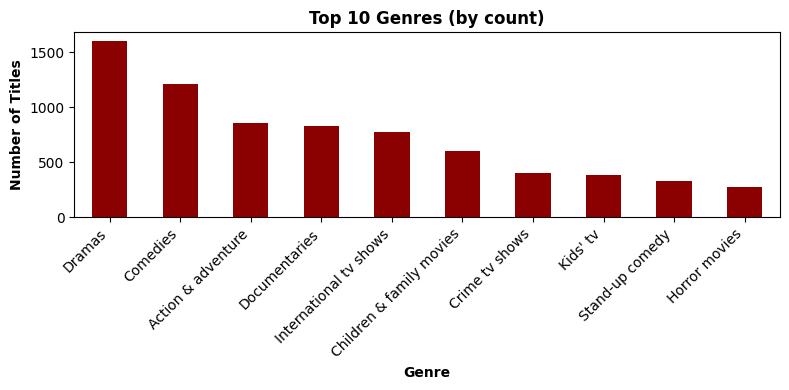

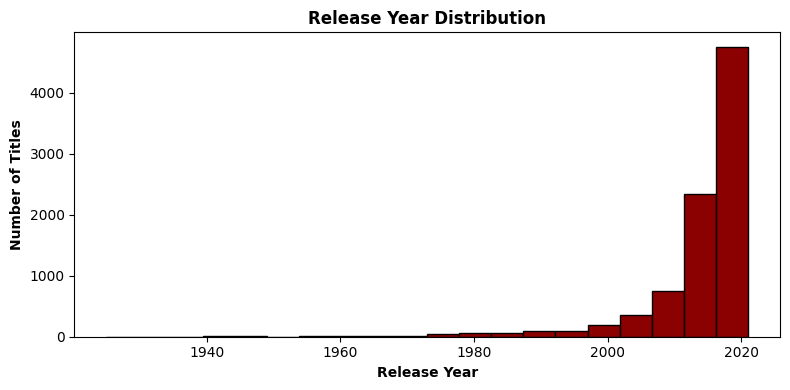

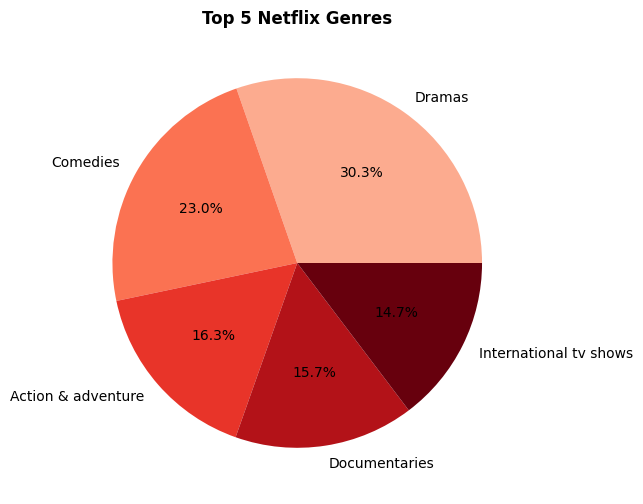

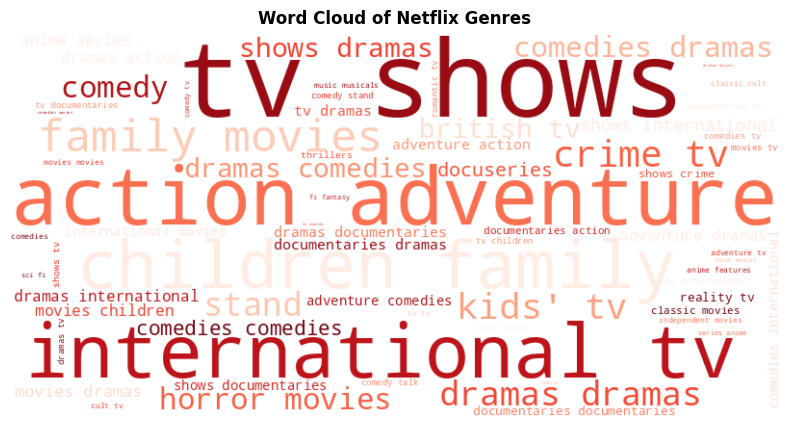

In [5]:
import os
import numpy as np
# Visualizations


# Bar chart of the top 10 most common genres
top_genres = df['genre'].str.capitalize().value_counts().head(10)
plt.figure(figsize=(8, 4))
top_genres.plot(kind='bar', color='darkred')
plt.title("Top 10 Genres (by count)", fontweight='bold')
plt.xlabel("Genre", fontweight='bold')
plt.ylabel("Number of Titles", fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
os.makedirs('images', exist_ok=True)
plt.savefig('images/top10_genres.png', dpi=150, bbox_inches='tight')
plt.show()

# Release year histogram
plt.figure(figsize=(8, 4))
plt.hist(df['release_year'], bins=20, color='darkred', edgecolor='black')
plt.title("Release Year Distribution", fontweight='bold')
plt.xlabel("Release Year", fontweight='bold')
plt.ylabel("Number of Titles", fontweight='bold')
plt.tight_layout()
plt.show()

# Top 5 genres pie chart
import numpy as np
import matplotlib.pyplot as plt

top5 = df['genre'].str.capitalize().value_counts().head(5)
plt.figure(figsize=(6,6))
plt.pie(
    top5.values,
    labels=top5.index,
    autopct='%1.1f%%',
    colors=plt.cm.Reds(np.linspace(0.3, 1, len(top5))),

)
plt.title("Top 5 Netflix Genres", fontweight='bold')
plt.show()

# Wordcloud of titles
from wordcloud import WordCloud
text = ' '.join(df['genre'])
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='Reds').generate(text)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Netflix Genres", fontweight='bold')
plt.show()




## 5. Train/test split and baseline

In [6]:
# Here we split the data into training and testing sets
# X = what we will feed into the model (text), y = what we want it to predict (genre)

X = df['text']
y = df['genre']

# Split 50% for training and 50% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.5,      # 50% test, 50% train
    random_state=42,    # fixed seed so the split (and the accuracy) is reproducible
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 4401
Testing samples: 4402


In [7]:
# Baseline: always predict the most common genre in the training set
# The model is only useful if it clearly beats this
majority_genre = y_train.value_counts().idxmax()
baseline_acc = (y_test == majority_genre).mean()
print(f"Majority genre: {majority_genre}")
print(f"Baseline accuracy: {baseline_acc:.4f} ({baseline_acc * 100:.2f}%)")

Majority genre: dramas
Baseline accuracy: 0.1822 (18.22%)


## 6. Train the model

In [8]:
# This cell turns text into numbers and train the Naive Bayes model, the actual machine learning model

vectorizer = CountVectorizer(
    max_features=7000       # This is to keep the 7,000 most frequent words in the description (when I tested this before without it the accuracy was 3-5% less than after adding)
)

# Here I fit the vectorizer on the training text
X_train_vec = vectorizer.fit_transform(X_train)

# Here I use the vectorizer to transform the test text
X_test_vec = vectorizer.transform(X_test)

# This is where I created the Naive Bayes classifier
nb_model = MultinomialNB()

# This is to train Naive Bayes model on the vectorized training part of the dataset
nb_model.fit(X_train_vec, y_train)

#Everything should work correctly after this and the model should be trained
print ("trained")

trained


## 7. Evaluate

In [9]:
# Here we evaluate how well the model does on the test data half of the file
# Use the trained model to predict genres for the test set
y_pred = nb_model.predict(X_test_vec)
# Check overall accuracy: what % of test titles got the correct genre
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")

# Show a more detailed breakdown by genre:
# precision, recall, and F1 score for each category
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Test Accuracy: 0.4205 (42.05%)

Classification Report:
                              precision    recall  f1-score   support

          action & adventure       0.47      0.48      0.47       448
              anime features       0.00      0.00      0.00        11
                anime series       0.00      0.00      0.00        79
            british tv shows       0.45      0.04      0.07       124
    children & family movies       0.46      0.50      0.48       299
           classic & cult tv       0.00      0.00      0.00         8
              classic movies       0.00      0.00      0.00        43
                    comedies       0.37      0.55      0.44       591
              crime tv shows       0.55      0.13      0.21       200
                 cult movies       0.00      0.00      0.00         6
               documentaries       0.48      0.73      0.58       398
                  docuseries       0.64      0.06      0.11       114
                      dramas      

## Results

With a fixed 50/50 split (`random_state=42`), the model reaches **42.05% accuracy** on 4,402 held-out titles across 33 genres, against an **18.22% baseline** that always predicts "dramas".

It does well on the large genres and almost never predicts the rare ones (anime features and anime series score 0), which matches the class imbalance seen in section 4.

Next steps: TF-IDF features with logistic regression, class weights or a stratified split for the imbalance, and multi-label prediction, since most titles list several genres.